# Le WASDE est-il le FOMC du blé ?
### Annonces USDA, surprise numérique et ton du texte face aux futures blé CBOT

*Projet — ML for Portfolio Management and Trading (M2 SFA, ENSAE Paris)*

Chaque mois, l'USDA publie le **WASDE** (*World Agricultural Supply and Demand Estimates*) : des tableaux de bilans offre/demande **et** des paragraphes narratifs par culture. On transpose au blé le cadre vu en cours pour les annonces de politique monétaire (event trading, prime d'annonce à la Savor & Wilson, sentiment textuel des communiqués FOMC).

**Trois hypothèses testées**

| | Hypothèse | Mesure |
|---|---|---|
| **H1** | Les jours de WASDE ont un rendement moyen et une volatilité anormaux (prime d'annonce) | rendements CBOT jour J vs autres jours |
| **H2** | La *surprise numérique* (révision des stocks de fin de campagne) explique la réaction du prix | régression du rendement sur la révision |
| **H3** (cœur) | Le *ton du texte* apporte de l'information **au-delà des chiffres** | Loughran-McDonald, Jegadeesh-Wu, LLM |

On finit par un **backtest** qui n'utilise que l'information disponible à la publication, et des **tests placebo** (maïs, soja, fausses dates).

**Plan du notebook**
0. Configuration
1. Données WASDE (scraping ESMIS / National Agricultural Library)
2. Parsing : paragraphes narratifs et chiffres clés
3. Prix des futures et traitement des *rolls*
4. Base événementielle
5. H1 — prime d'annonce et volatilité
6. H2 — surprise numérique
7. H3 — sentiment du texte (LM, Jegadeesh-Wu, LLM)
8. Information incrémentale du texte
9. Backtest
10. Placebos et robustesse
11. Limites et conclusion

## 0. Configuration

Le notebook est **entièrement reproductible** : toutes les données sont récupérées par code et mises en cache dans `data/`. Une première exécution complète télécharge ~300 rapports (quelques minutes, avec une pause entre requêtes pour ne pas surcharger le serveur de l'USDA). Les exécutions suivantes lisent le cache.

**Prérequis de données.** Le cache contient l'index ESMIS, les `.txt` des rapports et les PDF 2011-2026 (`data/wasde_pdf/`, environ 120 Mo, téléchargés une seule fois). Le notebook ne retélécharge que ce qui manque, avec une seule tentative par fichier. Deux éléments doivent être présents :
- `data/prices.csv` : clôtures et volumes des futures CBOT (colonnes `close_wheat`, `vol_wheat`, `close_corn`, …). Il est téléchargé une fois par yfinance si absent ; sans lui, les sections 3 à 10 ne s'exécutent pas.
- `data/Loughran-McDonald_MasterDictionary_1993-2021.csv` : copie de `skfin/data/`.
- `pdftotext` (paquet poppler) installé sur la machine, pour lire la narration des PDF.

Le score LLM (section 7.3) est optionnel : il ne tourne que si la variable d'environnement `ANTHROPIC_API_KEY` est définie.

In [1]:
# Dépendances (à lancer une fois)
# %pip install yfinance requests beautifulsoup4 statsmodels scikit-learn scipy matplotlib pysentiment2 anthropic

In [2]:
from pathlib import Path
import re, json, time, os, warnings
from urllib.parse import urljoin

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3})

DATA_DIR = Path("data")
TXT_DIR = DATA_DIR / "wasde_txt"
TXT_DIR.mkdir(parents=True, exist_ok=True)

START = "2000-01-01"            # début de l'historique de prix journaliers yfinance
FIRST_TEST_YEAR = 2008          # première année hors-échantillon (walk-forward)
TICKERS = {"wheat": "ZW=F", "corn": "ZC=F", "soy": "ZS=F"}   # futures continus CBOT
ESMIS_URL = "https://esmis.nal.usda.gov/publication/world-agricultural-supply-and-demand-estimates"
HEADERS = {"User-Agent": "Mozilla/5.0 (academic research project, ENSAE Paris)"}

USE_LLM = bool(os.environ.get("ANTHROPIC_API_KEY"))
LLM_MODEL = "claude-haiku-5-5"  # modèle peu coûteux ; ~900 appels au total
COST_BPS = 3                    # coût par aller simple (tick blé = 0,25 c/bu ≈ 0,4 bp + slippage)
SEED = 42
rng = np.random.default_rng(SEED)
print("LLM activé :", USE_LLM)

LLM activé : False


## 1. Données WASDE

Depuis le 1er octobre 2025, l'archive historique du WASDE n'est plus hébergée par la bibliothèque de Cornell mais par la **National Agricultural Library**, sur le portail **ESMIS**. La page de la publication liste chaque rapport depuis septembre 1973, avec des liens PDF / TXT / XLS / XML, sur ~70 pages paginées (`?page=0..70`).

On utilise le format **TXT** : il contient à la fois la narration (pages 1 à 7) et les tableaux en texte à largeur fixe.

> Remarque : quelques mois manquent dans l'archive (par exemple octobre 2025, non publié pendant le *shutdown* fédéral, ou certains mois des années 1970). On les laisse simplement de côté.

In [3]:
import requests
from bs4 import BeautifulSoup

def scrape_wasde_index(max_pages=90, sleep=0.5):
    # Liste (date de publication, URL du .txt) de tous les WASDE de l'archive ESMIS.
    cache = DATA_DIR / "wasde_index.csv"
    if cache.exists():
        return pd.read_csv(cache, parse_dates=["date"])
    rows = []
    for page in range(max_pages):
        r = requests.get(ESMIS_URL, params={"page": page}, headers=HEADERS, timeout=30)
        r.raise_for_status()
        soup = BeautifulSoup(r.text, "html.parser")
        n = 0
        for tr in soup.select("table tr"):
            tds = tr.find_all("td")
            if len(tds) < 2:
                continue
            date = pd.to_datetime(tds[0].get_text(strip=True), errors="coerce")
            if pd.isna(date):
                continue
            links = {a["href"].rsplit(".", 1)[-1].lower(): urljoin(ESMIS_URL, a["href"])
                     for a in tds[1].find_all("a", href=True)}
            rows.append({"date": date, "txt_url": links.get("txt"), "pdf_url": links.get("pdf")})
            n += 1
        if n == 0:          # page vide : fin de la pagination
            break
        time.sleep(sleep)
    idx = (pd.DataFrame(rows).drop_duplicates("date").sort_values("date").reset_index(drop=True))
    idx.to_csv(cache, index=False)
    return idx

def download_txt(idx, sleep=0.3):
    # Télécharge chaque rapport .txt (avec cache local). Renvoie {date: chemin}.
    paths = {}
    for d, url in zip(idx["date"], idx["txt_url"]):
        p = TXT_DIR / f"{d:%Y-%m-%d}.txt"
        if not p.exists():
            if not isinstance(url, str):
                continue
            r = requests.get(url, headers=HEADERS, timeout=60)
            if r.status_code != 200:
                continue
            p.write_bytes(r.content)
            time.sleep(sleep)
        paths[d] = p
    return paths

PDF_DIR = DATA_DIR / "wasde_pdf"   # PDF ESMIS : narration pages 1-7 (2011-2026), utilisée quand le .txt ne la contient pas

def download_pdf(idx, sleep=0.5):
    # PDF de chaque rapport 2011-2026 (cache local). Une tentative par rapport : les échecs sont listés
    # dans _failed.txt et ne sont pas réessayés à chaque exécution. Renvoie (nouveaux, échecs).
    PDF_DIR.mkdir(parents=True, exist_ok=True)
    failed_file = PDF_DIR / "_failed.txt"
    failed = set(failed_file.read_text().split()) if failed_file.exists() else set()
    new_fail, n_new = [], 0
    for d, url in zip(idx["date"], idx["pdf_url"]):
        p = PDF_DIR / f"{d:%Y-%m-%d}.pdf"
        if d < pd.Timestamp("2011-01-01") or p.exists() or not isinstance(url, str) or f"{d:%Y-%m-%d}" in failed:
            continue
        try:
            r = requests.get(url, headers=HEADERS, timeout=60)
            if r.status_code == 200 and r.content[:4] == b"%PDF":
                p.write_bytes(r.content); n_new += 1
            else:
                new_fail.append(f"{d:%Y-%m-%d}\t{r.status_code}")
        except requests.RequestException as e:
            new_fail.append(f"{d:%Y-%m-%d}\t{type(e).__name__}")
        time.sleep(sleep)
    if new_fail:
        failed_file.write_text("\n".join(sorted(failed) + new_fail) + "\n")
    return n_new, len(new_fail)

wasde_idx = scrape_wasde_index()
wasde_idx = wasde_idx[wasde_idx["date"] >= START].reset_index(drop=True)
paths = download_txt(wasde_idx)
print(f"{len(wasde_idx)} rapports listés depuis {START}, {len(paths)} fichiers .txt disponibles")
n_new, n_fail = download_pdf(wasde_idx)
print(f"PDF ESMIS 2011-2026 : {n_new} téléchargés, {n_fail} échecs, {len(list(PDF_DIR.glob('*.pdf')))} en cache")
wasde_idx.tail()

330 rapports listés depuis 2000-01-01, 255 fichiers .txt disponibles
PDF ESMIS 2011-2026 : 0 téléchargés, 0 échecs, 188 en cache


,date,txt_url,pdf_url
325,2026-06-11,https://esmis.nal.usda.gov/sites/default/relea...,https://esmis.nal.usda.gov/sites/default/relea...
326,2026-07-10,https://esmis.nal.usda.gov/sites/default/relea...,https://esmis.nal.usda.gov/sites/default/relea...
327,2026-08-12,https://esmis.nal.usda.gov/sites/default/relea...,https://esmis.nal.usda.gov/sites/default/relea...
328,2026-09-11,https://esmis.nal.usda.gov/sites/default/relea...,https://esmis.nal.usda.gov/sites/default/relea...
329,2026-10-09,https://esmis.nal.usda.gov/sites/default/relea...,https://esmis.nal.usda.gov/sites/default/relea...


## 2. Parsing des rapports

### 2.1 Les paragraphes narratifs

La narration précède le premier tableau (*World and U.S. Supply and Use for Grains*). Elle est découpée en sections qui commencent par un libellé en majuscules suivi de deux-points : `WHEAT:`, `COARSE GRAINS:`, `RICE:`, `OILSEEDS:`, `SUGAR:`, `LIVESTOCK, POULTRY, AND DAIRY:`, `COTTON:`. On extrait les sections blé, céréales secondaires (maïs) et oléagineux (soja). Les deux dernières servent à **mutualiser** l'apprentissage Jegadeesh-Wu et aux **placebos**.

### 2.2 Les chiffres clés : la surprise mesurée par la révision

Faute de consensus d'analystes accessible publiquement (les sondages Reuters/Bloomberg pré-WASDE sont payants), la **surprise** est mesurée comme la **révision par rapport au rapport précédent**. Le format des tableaux rend ce calcul direct : pour la campagne en cours, chaque tableau donne côte à côte la projection du mois précédent et celle du mois courant (par ex. colonnes `Sep` et `Oct`).

Variables extraites :
- `us_es`, `us_es_rev` : stocks de fin de campagne US de blé (millions de boisseaux) et révision relative ;
- `world_es`, `world_es_rev` : stocks mondiaux de blé (millions de tonnes) et révision relative ;
- `corn_es_rev`, `soy_es_rev` : idem pour maïs et soja (placebos / extension).

Le rapport de **mai** introduit la nouvelle campagne : il n'y a pas de projection précédente pour comparer, la révision y vaut donc `NaN`.

> **Constat à l'exécution.**
> - **2000 – 2010** : la narration est dans le `.txt`. Le libellé `WHEAT:` est présent dans tous les rapports : le taux d'extraction du paragraphe blé est de 100 % quand la narration existe. La casse et les espaces ne sont pas en cause.
> - **2011 – 2026** : le `.txt` ne contient pas la narration à partir de 2016 (il commence à la page 8), et n'existe pas pour 2011-2015 (l'index ne donne que le PDF). La narration vient donc du **PDF ESMIS** (pages 1 à 7, lues avec `pdftotext`). Le libellé `WHEAT:` est présent dans les 188 PDF. Les 188 PDF sont dans `data/wasde_pdf/` (≈ 120 Mo, téléchargés une seule fois).
> - **Tableaux de stocks** : lus dans le `.txt` quand il existe, sinon dans le PDF en mise en page conservée (2011-2015, et 9 rapports de 2016). Contrôle sur les 110 rapports qui ont les deux sources : révision du blé et du soja identique à 100 %. Pour le maïs, 74 % exacts et 95 % à moins de 0,5 point, car le PDF donne les tonnes à une décimale et le `.txt` les boisseaux.
> - **Hors WASDE** : 2001-09-11, 2008-05-07 (communiqué OCE), 2009-09-14 (avis de remplacement) et 2010-12-15 (communiqué du Secrétaire) sont exclus. 2008-10-28 (WASDE-463-Revised) est gardé, sans narration.

Conséquence : H2 utilise désormais 2000-2026 (256 observations), et H3 176 observations hors échantillon avec révisions de stocks.

In [4]:
# Format vérifié sur 2000-01, 2003-02, 2008-05, 2010-06 : libellé en capitales suivi de « : ».
# La casse et les espaces ne sont pas en cause. Depuis 2016 le .txt ne contient plus la narration
# (il commence à la page 8) : aucune regex ne peut la retrouver, voir section 2.1 et cellule de couverture.
LABEL_RE = re.compile(r"^\s*(WHEAT|COARSE GRAINS|RICE|OILSEEDS|SUGAR|COTTON|LIVESTOCK[A-Z ,&]*)\s*:", re.M)
SECTION_KEY = {"WHEAT": "wheat", "COARSE GRAINS": "corn", "OILSEEDS": "soy"}
PAGE_HEADER_RE = re.compile(r"WASDE\s*-\s*\d+\s*-\s*\d+[^\n]*")
MONTH_LINE_RE = re.compile(r"^\s+(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)\S*\s*:?\s+-?\d")

def read_txt(p):
    return Path(p).read_bytes().decode("latin-1", errors="ignore").replace("\r", "")

# En-tête d'un rapport WASDE (« WASDE - 570 - 8 », « WASDE-362 ») ou d'un tableau de bilans.
# Absent des communiqués OCE, avis de remplacement et communiqués du Secrétaire, qui sont exclus.
WASDE_HDR_RE = re.compile(r"WASDE\s*-?\s*\d+|World and U\.?S\.? Supply and Use|U\.S\. Wheat Supply and Use")

def narrative_part(text):
    # Titre du tableau de synthèse : « U.S. » avec ou sans point final selon les années (2017 : « U.S Supply »).
    # Pas de titre = pas de narration (sans repli sur le début du texte, qui pourrait être un tableau).
    m = re.search(r"World and U\.?S\.? Supply and Use for Grains", text)
    return text[: m.start()] if m else ""

def extract_sections(text):
    narr = narrative_part(text)
    hits = list(LABEL_RE.finditer(narr))
    out = {}
    for i, h in enumerate(hits):
        key = SECTION_KEY.get(h.group(1).strip())
        if key is None or key in out:
            continue
        end = hits[i + 1].start() if i + 1 < len(hits) else len(narr)
        body = PAGE_HEADER_RE.sub(" ", narr[h.end(): end])
        out[key] = re.sub(r"\s+", " ", body).strip()
    return out

def nums(line):
    # Nombres d'une ligne de tableau ; ignore les années '2024/25' et les renvois '2/'.
    return [float(x.replace(",", "")) for x in
            re.findall(r"(?<![\w/.])-?\d[\d,]*\.?\d*(?![\w/])", line)]

def nums_na(line):
    # Comme nums, mais « NA » (valeur non publiée, p. ex. avril avant le rapport de mai) devient NaN
    # et garde sa colonne : indispensable pour les tableaux des PDF.
    out = []
    for tok in line.split():
        if tok == "NA":
            out.append(np.nan)
        elif re.fullmatch(r"-?[\d,]*\d\.?\d*", tok):
            out.append(float(tok.replace(",", "")))
    return out

def block(text, title_re, n=70):
    m = re.search(title_re, text)
    return None if m is None else text[m.end():].splitlines()[:n]

def us_table_revision(text, title_re, after_re=None):
    # (niveau courant, révision relative) des stocks de fin dans un tableau 'U.S. ... Supply and Use'.
    # NB : en mai (1er mois de la nouvelle campagne), une seule colonne de projection existe donc
    # la ligne "Ending Stocks" n'a que 3 nombres -> le test len(v) >= 4 ci-dessous l'exclut déjà ;
    # inutile (et trompeur, cf. format pré-2012 "Projections" au singulier) de pré-filtrer sur "Proj".
    lines = block(text, title_re)
    if lines is None:
        return np.nan, np.nan
    start = 0
    if after_re:
        # after_re : un motif ou une liste de motifs, essayés dans l'ordre.
        pats = [after_re] if isinstance(after_re, str) else after_re
        start = next((i for p in pats for i, l in enumerate(lines) if re.search(p, l)), None)
        if start is None:
            return np.nan, np.nan
    for l in lines[start:]:
        if re.match(r"^\s*Ending [Ss]tocks\s*:?\s+-?\d", l):
            v = nums_na(l)
            if len(v) >= 4 and v[-2] != 0:
                return v[-1], v[-1] / v[-2] - 1
            break
    return np.nan, np.nan

def world_summary_revision(text, region="World", commodity="Wheat"):
    # Stocks de fin (dernière colonne) des deux lignes mensuelles du tableau de synthèse Grains.
    # titre : "U.S" sans point final dans certains rapports -> "\.?" ; lignes région/produit
    # préfixées par ":" dans le format pré-2012 -> on l'enlève avant de comparer.
    lines = block(text, r"World and U\.S\.?\s+Supply and Use for Grains", 60)
    if lines is None:
        return np.nan, np.nan
    try:
        i = next(k for k, l in enumerate(lines) if l.replace(":", "").strip() == region)
        j = next(k for k in range(i + 1, len(lines)) if lines[k].replace(":", "").strip().startswith(commodity))
    except StopIteration:
        return np.nan, np.nan
    months = []
    for l in lines[j + 1: j + 8]:
        if MONTH_LINE_RE.match(l):
            months.append(nums(l)[-1])
        elif months or not l.startswith(" "):
            break
    if len(months) == 2 and months[0] != 0:
        return months[1], months[1] / months[0] - 1
    return np.nan, np.nan

import subprocess   # pdftotext (outil local) pour la narration des PDF

def pdf_text(d):
    # Texte d'un PDF ESMIS. Vide si le PDF n'est pas en cache (avant 2011 la narration est dans le .txt).
    p = PDF_DIR / f"{d:%Y-%m-%d}.pdf"
    if not p.exists():
        return ""
    return subprocess.run(["pdftotext", "-q", str(p), "-"], capture_output=True, text=True,
                          encoding="utf-8", errors="ignore").stdout

def pdf_layout(d):
    # Texte en mise en page conservée (colonnes des tableaux) d'un PDF ESMIS ; vide si absent.
    p = PDF_DIR / f"{d:%Y-%m-%d}.pdf"
    if not p.exists():
        return ""
    return subprocess.run(["pdftotext", "-q", "-layout", str(p), "-"], capture_output=True, text=True,
                          encoding="utf-8", errors="ignore").stdout

def world_pdf_revision(text):
    # PDF : bloc « World », ligne « Wheat », puis lignes « 2012/13 (Proj.) Apr / May ».
    # Stocks = dernière colonne ; révision = mois courant / mois précédent de la même campagne.
    lines = block(text, r"World and U\.S\.?\s+Supply and Use for Grains", 80)
    if lines is None:
        return np.nan, np.nan
    try:
        i = next(k for k, l in enumerate(lines) if l.strip() == "World")
        j = next(k for k in range(i + 1, len(lines)) if lines[k].strip().startswith("Wheat"))
    except StopIteration:
        return np.nan, np.nan
    # Le bloc du blé s'arrête à la ligne suivante de produit (texte non indenté).
    end = next((k for k in range(j + 1, len(lines)) if re.match(r"^\S", lines[k])), len(lines))
    proj = []
    for l in lines[j + 1: end]:
        m = re.match(r"^\s*(\d{4}/\d{2}) \(Proj\.\)", l)
        if m:
            v = nums_na(l)
            proj.append((m.group(1), v[-1] if v else np.nan))
    if not proj:
        return np.nan, np.nan
    last_crop, last = proj[-1]
    if len(proj) >= 2 and proj[-2][0] == last_crop and proj[-2][1] and not np.isnan(proj[-2][1]):
        return last, last / proj[-2][1] - 1
    return last, np.nan

def parse_report(date):
    # Narration : le .txt si elle y est, sinon le PDF (2016-2026 : le .txt commence à la page 8).
    # Tableaux : le .txt si présent, sinon le PDF en mise en page conservée (2011-2015 et 9 rapports de 2016).
    txt = read_txt(paths[date]) if date in paths else ""
    pdf = pdf_text(date)
    narr_src = next((s for s, t in (("txt", txt), ("pdf", pdf)) if len(narrative_part(t)) >= 1000), "")
    sec = extract_sections(txt if narr_src == "txt" else pdf) if narr_src else {}
    tab = txt if txt else pdf_layout(date)
    us_es, us_rev = us_table_revision(tab, r"U\.S\. Wheat Supply and Use")
    w_es, w_rev = world_summary_revision(txt, "World", "Wheat") if txt else world_pdf_revision(tab)
    _, corn_rev = us_table_revision(tab, r"U\.S\. Feed Grain and Corn Supply and Use",
                                    [r"^\s*CORN\s*$", r"^\s*FEED GRAINS\s*$"])
    _, soy_rev = us_table_revision(tab, r"U\.S\. Soybeans and Products Supply and Use", r"^\s*SOYBEANS\s*$")
    return {"date": date, "is_wasde": bool(WASDE_HDR_RE.search(txt or pdf)), "narr_src": narr_src or "aucune",
            "narr_len": len(narrative_part(txt if narr_src == "txt" else pdf)),
            "txt_wheat": sec.get("wheat"), "txt_corn": sec.get("corn"), "txt_soy": sec.get("soy"),
            "us_es": us_es, "us_es_rev": us_rev, "world_es": w_es, "world_es_rev": w_rev,
            "corn_es_rev": corn_rev, "soy_es_rev": soy_rev}

# Rapports 2011-2026 disponibles seulement en PDF inclus ; un rapport = un .txt ou un PDF.
pdf_dates = [d for d in wasde_idx["date"] if (PDF_DIR / f"{d:%Y-%m-%d}.pdf").exists()]
dates = sorted(set(paths) | set(pdf_dates))
rep = pd.DataFrame([parse_report(d) for d in dates])
hors = rep.loc[~rep["is_wasde"], "date"].dt.strftime("%Y-%m-%d").tolist()
print("Fichiers listés mais qui ne sont pas un rapport WASDE (communiqué, avis de remplacement), exclus :", hors)
rep = rep[rep["is_wasde"]].reset_index(drop=True)
print("Source de la narration :", rep["narr_src"].value_counts().to_dict())
# Contrôle : révisions lues dans le PDF (layout) vs dans le .txt, sur les rapports qui ont les deux.
both = [d for d in rep["date"] if d in paths and (PDF_DIR / f"{d:%Y-%m-%d}.pdf").exists()]
for nom, title, after in [("blé", r"U\.S\. Wheat Supply and Use", None),
                          ("maïs", r"U\.S\. Feed Grain and Corn Supply and Use", [r"^\s*CORN\s*$", r"^\s*FEED GRAINS\s*$"]),
                          ("soja", r"U\.S\. Soybeans and Products Supply and Use", r"^\s*SOYBEANS\s*$")]:
    ctl = pd.DataFrame([{"txt": us_table_revision(read_txt(paths[d]), title, after)[1],
                         "pdf": us_table_revision(pdf_layout(d), title, after)[1]} for d in both]).dropna()
    if len(ctl):
        ecart = (ctl.txt - ctl.pdf).abs()
        print(f"Contrôle PDF vs .txt, révision US {nom} : {len(ctl)} rapports ; identiques {(ecart < 1e-9).mean():.0%} ; "
              f"à moins de 0,5 pt {(ecart < 0.005).mean():.0%} ; même signe {(np.sign(ctl.txt) == np.sign(ctl.pdf)).mean():.0%}")
rep["n_words_wheat"] = rep["txt_wheat"].fillna("").str.split().str.len()

# Une narration « présente » fait plusieurs milliers de caractères ; une page de titre seule fait ~140.
rep["has_narr"] = rep["narr_len"] >= 1000

by_year = lambda d: d.assign(year=d.date.dt.year).groupby("year")
cov = by_year(rep).agg(
    n_rapports=("date", "size"),
    narr_txt=("narr_src", lambda s: (s == "txt").sum()),
    narr_pdf=("narr_src", lambda s: (s == "pdf").sum()),
    rev_US=("us_es_rev", lambda s: s.notna().mean()),
    rev_monde=("world_es_rev", lambda s: s.notna().mean()))
# Taux de texte calculé seulement sur les rapports qui ont une narration (sinon 0 par construction).
cov["texte_blé | narration"] = by_year(rep[rep.has_narr]).txt_wheat.apply(lambda s: s.notna().mean())
print("« rev_US » = part des rapports dont la révision des stocks US est extraite (tableaux du .txt).")
display(cov.T)
absents = wasde_idx[~wasde_idx["date"].isin(rep["date"])]
print("Rapports de l'index sans fichier (ni txt ni PDF), par année :", absents.groupby(absents.date.dt.year).size().to_dict())


Fichiers listés mais qui ne sont pas un rapport WASDE (communiqué, avis de remplacement), exclus : ['2001-09-11', '2008-05-07', '2009-09-14', '2010-12-15']
Source de la narration : {'pdf': 188, 'txt': 130, 'aucune': 1}


Contrôle PDF vs .txt, révision US blé : 110 rapports ; identiques 100% ; à moins de 0,5 pt 100% ; même signe 100%


Contrôle PDF vs .txt, révision US maïs : 110 rapports ; identiques 74% ; à moins de 0,5 pt 95% ; même signe 97%


Contrôle PDF vs .txt, révision US soja : 110 rapports ; identiques 100% ; à moins de 0,5 pt 100% ; même signe 100%
« rev_US » = part des rapports dont la révision des stocks US est extraite (tableaux du .txt).


year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
n_rapports,12.0000,12.0000,12.0000,12.0000,12.0000,12.0000,12.0000,12.0000,14.0000,12.0000,...,12.0000,13.0000,11.0000,12.0000,12.0000,12.0000,12.0000,12.0000,11.0000,10.0000
narr_txt,12.0000,12.0000,12.0000,12.0000,12.0000,12.0000,12.0000,12.0000,13.0000,12.0000,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
narr_pdf,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,12.0000,13.0000,11.0000,12.0000,12.0000,12.0000,12.0000,12.0000,11.0000,10.0000
rev_US,0.9167,0.9167,0.9167,0.9167,0.9167,0.9167,0.9167,0.9167,0.8571,0.9167,...,0.9167,0.9231,0.9091,0.9167,0.9167,0.9167,0.9167,0.9167,0.9091,0.9000
rev_monde,0.9167,0.9167,0.9167,0.9167,0.9167,0.9167,0.9167,0.9167,0.8571,0.9167,...,0.9167,0.9231,0.9091,0.9167,0.9167,0.9167,0.9167,0.9167,0.9091,0.9000
texte_blé | narration,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,...,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


Rapports de l'index sans fichier (ni txt ni PDF), par année : {2001: 2, 2008: 3, 2009: 1, 2010: 4, 2014: 1}


In [5]:
# Contrôle visuel : un paragraphe blé et les chiffres associés
sub = rep.dropna(subset=["txt_wheat", "us_es_rev"])
if sub.empty:
    print("Aucun rapport avec paragraphe blé et révision US : vérifier parse_report.")
else:
    ex = sub.iloc[-1]                       # ex est une ligne (Series) : on accède aux champs par ex["date"]
    print(f"Rapport du {ex['date']:%Y-%m-%d} | révision stocks US de blé : {ex['us_es_rev']:+.2%}")
    print(ex["txt_wheat"][:1200], "...")

Rapport du 2026-10-09 | révision stocks US de blé : +3.21%
The outlook for 2026/27 U.S. wheat this month is for higher supplies, increased domestic use, reduced exports, and greater ending stocks. Supplies are raised by 8 million bushels on higher imports and production. The NASS Small Grains Annual Summary estimated wheat production slightly greater at 1,534 million bushels on an increased yield more than offsetting reduced harvested area. Despite the increase, this remains the smallest U.S. wheat production since 1970. Domestic use is raised 10 million bushels, all on higher feed and residual use. The NASS Grain Stocks report implied larger-than-previouslyexpected first quarter (June-August) domestic disappearance. Exports are reduced 25 million bushels to 750 million on lower sales and shipments to date for Hard Red Winter (HRW) and Hard Red Spring that are partially offset by increased White exports. HRW is the largest decline as HRW continues to be uncompetitive in export markets 

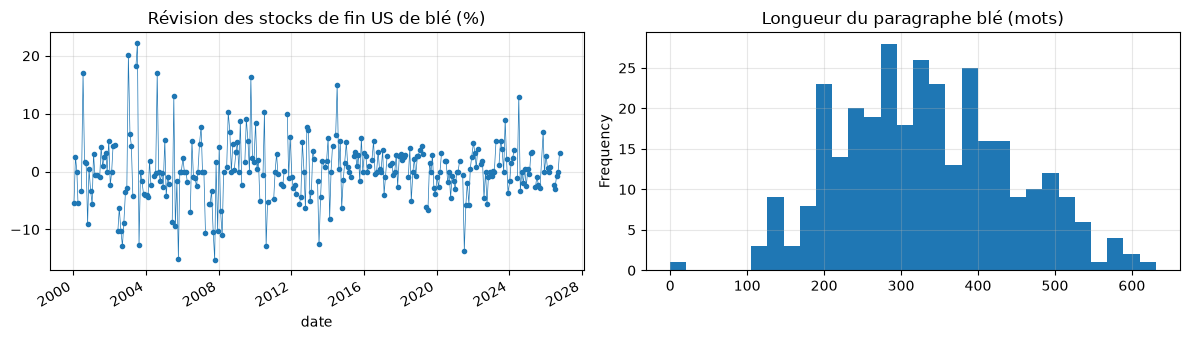

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
rep.set_index("date")["us_es_rev"].mul(100).plot(ax=ax[0], marker=".", lw=.5,
    title="Révision des stocks de fin US de blé (%)")
rep["n_words_wheat"].plot.hist(ax=ax[1], bins=30, title="Longueur du paragraphe blé (mots)")
plt.tight_layout()

## 3. Prix des futures et traitement des *rolls*

On utilise les futures continus CBOT de `yfinance` : blé `ZW=F`, maïs `ZC=F`, soja `ZS=F`, en journalier depuis 2000.

**Piège du contrat continu.** `ZW=F` colle bout à bout les contrats successifs (mars, mai, juillet, septembre, décembre). Au changement de contrat, le prix saute de l'écart entre les deux échéances (le *spread* calendaire). Ce saut n'est pas un rendement réalisable, et il tombe souvent à la mi-mois du mois de livraison, **à quelques jours du WASDE** (publié autour du 9-12). S'il n'est pas traité, il pollue précisément les rendements de jour d'annonce.

**Méthode de détection, indépendante des rendements.** On évite de repérer les rolls par la taille des rendements : on risquerait de « nettoyer » de vraies réactions au WASDE. On utilise plutôt le **volume** : au roll, le contrat continu passe d'une échéance qui expire (volume résiduel faible) à la suivante (volume élevé), ce qui crée un saut de volume caractéristique. Dans une fenêtre autour de la dernière séance de négociation théorique (jour ouvré précédant le 15 du mois de livraison), on retient le jour de plus forte hausse du log-volume, s'il dépasse un facteur 3. Le rendement de ce jour est neutralisé (`NaN`).

> Alternative plus propre si vous y avez accès : reconstruire une série *back-adjusted* à partir des contrats individuels (Barchart, Nasdaq Data Link…). La fonction `load_prices` accepte un CSV de remplacement au même format.

> **Diagnostic (exécution).** Aucun des 15 plus gros rendements bruts du blé n'est un roll détecté : la vérification demandée passe, la fenêtre n'a pas été modifiée. Sur 131 rolls blé, 118 tombent le jour même de la dernière séance théorique. Neuf rolls tombent plus de 4 jours calendaires avant : ce sont des pics de volume à surveiller. Neuf jours de WASDE coïncident exactement avec un roll : le rendement de ce jour contient le spread calendaire. Il est mis à `NaN` et l'événement est perdu, car un rendement journalier ne permet pas de séparer les deux effets. Ces cas sont à signaler dans le rapport.

In [7]:
CONTRACT_MONTHS = {"wheat": [3, 5, 7, 9, 12], "corn": [3, 5, 7, 9, 12], "soy": [1, 3, 5, 7, 8, 9, 11]}

def load_prices():
    # Clôtures et volumes journaliers. Cache : data/prices.csv (colonnes close_<x>, vol_<x>).
    cache = DATA_DIR / "prices.csv"
    if cache.exists():
        return pd.read_csv(cache, index_col=0, parse_dates=True)
    import yfinance as yf
    raw = yf.download(list(TICKERS.values()), start=START, auto_adjust=False, progress=False)
    inv = {v: k for k, v in TICKERS.items()}
    px = pd.concat({f"close_{inv[t]}": raw["Close"][t] for t in TICKERS.values()} |
                   {f"vol_{inv[t]}": raw["Volume"][t] for t in TICKERS.values()}, axis=1)
    px.index = pd.to_datetime(px.index).tz_localize(None)
    px.to_csv(cache)
    return px

def last_trading_days(comm, years):
    # Approximation CBOT grains : jour ouvré précédant le 15 du mois de livraison (hors jours fériés).
    return pd.DatetimeIndex([pd.Timestamp(y, m, 15) - pd.offsets.BDay(1)
                             for y in years for m in CONTRACT_MONTHS[comm]])

def detect_rolls(vol, comm, before=25, after=3, min_jump=np.log(3)):
    dlv = np.log(vol.replace(0, np.nan)).diff()
    rolls = []
    for d in last_trading_days(comm, range(vol.index.year.min(), vol.index.year.max() + 1)):
        w = dlv.loc[d - pd.offsets.BDay(before): d + pd.offsets.BDay(after)].dropna()
        if len(w) and w.max() > min_jump:
            rolls.append(w.idxmax())
    return pd.DatetimeIndex(rolls)

px = load_prices()
rets, raw_rets, rolls, sig = {}, {}, {}, {}
for c in TICKERS:
    close = px[f"close_{c}"].dropna()
    r = np.log(close).diff()
    raw_rets[c] = r.copy()
    rolls[c] = detect_rolls(px[f"vol_{c}"].reindex(close.index), c).intersection(r.index)
    r.loc[rolls[c]] = np.nan
    rets[c] = r
    sig[c] = r.rolling(60, min_periods=20).std().shift(1)    # volatilité ex ante (info jusqu'à t-1)

for c in TICKERS:
    rr = raw_rets[c]
    print(f"{c:6s} : {len(rolls[c])} rolls détectés | |rendement| moyen aux rolls "
          f"{rr.loc[rolls[c]].abs().mean():.2%} vs {rr.abs().mean():.2%} les autres jours")

wheat  : 131 rolls détectés | |rendement| moyen aux rolls 1.38% vs 1.52% les autres jours
corn   : 130 rolls détectés | |rendement| moyen aux rolls 1.35% vs 1.26% les autres jours
soy    : 165 rolls détectés | |rendement| moyen aux rolls 1.27% vs 1.09% les autres jours


In [8]:
# Diagnostic : les rendements bruts les plus extrêmes tombent-ils sur des rolls ?
top = raw_rets["wheat"].abs().nlargest(15).to_frame("abs_ret")
top["roll_détecté"] = top.index.isin(rolls["wheat"])
top

,abs_ret,roll_détecté
Date,,
2022-03-03,0.1970,False
2022-03-08,0.1130,False
2022-03-10,0.1107,False
2009-01-12,0.0997,False
2022-02-28,0.0961,False
2022-02-25,0.0939,False
2011-06-30,0.0922,False
2008-02-28,0.0907,False
2008-10-29,0.0879,False


## 4. Base événementielle

Pour chaque rapport et chaque céréale, on aligne la date de publication sur la séance correspondante :

- `r0` : rendement log **clôture J-1 → clôture J** (le jour de publication) ;
- `z0 = r0 / σ` : rendement normalisé par la volatilité ex ante (60 jours jusqu'à J-1), pour comparer des périodes calmes et agitées (2008, 2010, 2022) ;
- `r_pre` : rendement de la veille (anticipation, fuites) ;
- `r_post1`, `r_post5` : rendements de J+1 et cumulés de J+1 à J+5 (dérive post-annonce, **la seule partie négociable** avec des données journalières).

**Heure de publication.** Le WASDE sort aujourd'hui à **12h00 heure de New York**, en pleine séance CBOT. Jusqu'au début des années 2010, il sortait à 8h30, avant l'ouverture. Dans les deux cas, le rendement clôture-à-clôture de J contient l'annonce, mais depuis le passage à midi il contient aussi la matinée qui précède, ce qui ajoute du bruit. On contrôle ce changement de régime avec une indicatrice `post2013`.

In [9]:
def build_events(rep, rets, sig):
    rows = []
    for c in TICKERS:
        r, s = rets[c], sig[c]
        idx = r.index
        for d in rep["date"]:
            pos = idx.searchsorted(d)
            if pos >= len(idx) - 6 or pos < 1 or (idx[pos] - d).days > 3:
                continue
            rows.append({"date": d, "comm": c, "tday": idx[pos],
                         "r0": r.iloc[pos], "sig": s.iloc[pos], "r_pre": r.iloc[pos - 1],
                         "r_post1": r.iloc[pos + 1], "r_post5": r.iloc[pos + 1: pos + 6].sum(min_count=3)})
    ev = pd.DataFrame(rows)
    ev["z0"] = ev["r0"] / ev["sig"]
    ev["post2013"] = (ev["date"] >= "2013-01-01").astype(int)
    return ev

events = build_events(rep, rets, sig).merge(rep, on="date", how="left")
ew = events[events.comm == "wheat"].dropna(subset=["r0"]).reset_index(drop=True)
print(f"{len(ew)} événements blé exploitables ({ew.date.min():%Y-%m} → {ew.date.max():%Y-%m}); "
      f"{events.loc[events.comm == 'wheat', 'r0'].isna().sum()} événements blé écartés car tombant sur un roll")
print("Événements blé par année :", ew.groupby(ew.date.dt.year).size().to_dict())
ew[["date", "r0", "z0", "us_es_rev", "world_es_rev", "r_post1"]].describe().T

304 événements blé exploitables (2000-08 → 2026-10); 8 événements blé écartés car tombant sur un roll
Événements blé par année : {2000: 5, 2001: 12, 2002: 11, 2003: 12, 2004: 12, 2005: 12, 2006: 11, 2007: 12, 2008: 12, 2009: 12, 2010: 9, 2011: 12, 2012: 12, 2013: 11, 2014: 12, 2015: 12, 2016: 12, 2017: 12, 2018: 12, 2019: 11, 2020: 12, 2021: 12, 2022: 12, 2023: 11, 2024: 11, 2025: 10, 2026: 10}


,count,mean,min,25%,50%,75%,max,std
date,304,2013-08-12 23:17:22.105263,2000-08-11 00:00:00,2007-02-02 00:00:00,2013-08-27 12:00:00,2020-02-18 00:00:00,2026-10-09 00:00:00,NaN
r0,304.0000,-0.0030,-0.0997,-0.0167,-0.0038,0.0109,0.0841,0.0227
z0,303.0000,-0.1498,-3.1726,-0.9413,-0.2008,0.6585,3.5962,1.1113
us_es_rev,278.0000,0.0017,-0.1519,-0.0236,0.0000,0.0284,0.2219,0.0526
world_es_rev,258.0000,0.0023,-0.0694,-0.0070,0.0018,0.0110,0.3147,0.0276
r_post1,280.0000,0.0008,-0.1107,-0.0117,0.0007,0.0117,0.0879,0.0210


## 5. H1 — Prime d'annonce et volatilité anormale

Version « matières premières » de Savor & Wilson : les rendements sont-ils plus élevés (rémunération d'un risque macro/agricole concentré sur ces dates) et plus volatils les jours de WASDE ?

Tests : différence de moyennes (Welch), test de rang (Mann-Whitney) et régressions sur une indicatrice d'annonce, avec écarts-types **HAC (Newey-West)**.

In [10]:
def announcement_table(c, event_days):
    r = rets[c].dropna()
    d = pd.DataFrame({"r": r, "abs_r": r.abs(), "z_abs": (r / sig[c]).abs()}).dropna()
    d["wasde"] = d.index.isin(event_days).astype(int)
    out = {}
    for col in ["r", "abs_r", "z_abs"]:
        a, b = d.loc[d.wasde == 1, col], d.loc[d.wasde == 0, col]
        ols = smf.ols(f"{col} ~ wasde", d).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
        out[col] = {"moy. WASDE": a.mean(), "moy. autres": b.mean(), "ratio": a.mean() / b.mean() if col != "r" else np.nan,
                    "t HAC": ols.tvalues["wasde"], "p Welch": stats.ttest_ind(a, b, equal_var=False).pvalue,
                    "p Mann-Whitney": stats.mannwhitneyu(a, b).pvalue, "n WASDE": len(a)}
    return pd.DataFrame(out).T

ev_days = {c: pd.DatetimeIndex(events.loc[events.comm == c, "tday"]) for c in TICKERS}
h1 = announcement_table("wheat", ev_days["wheat"])
h1

,moy. WASDE,moy. autres,ratio,t HAC,p Welch,p Mann-Whitney,n WASDE
r,-0.0030,0.0003,NaN,-2.5180,0.0126,0.0070,303.0000
abs_r,0.0174,0.0151,1.1537,2.7314,0.0078,0.0037,303.0000
z_abs,0.8971,0.7922,1.1324,2.6526,0.0083,0.0011,303.0000


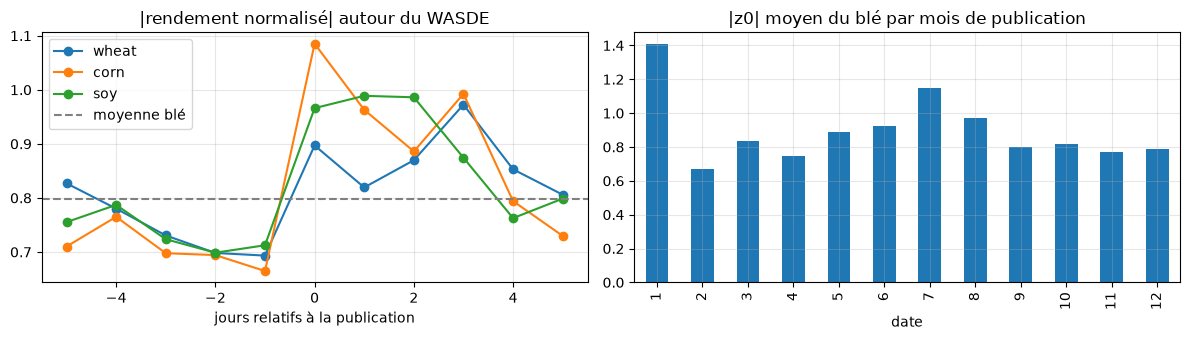

In [11]:
# Profil en temps événementiel : |z| moyen de J-5 à J+5
def event_profile(c, days, k=5):
    z = (rets[c] / sig[c]).abs()
    idx = z.index
    prof = {}
    for j in range(-k, k + 1):
        pos = idx.searchsorted(days) + j
        pos = pos[(pos >= 0) & (pos < len(idx))]
        prof[j] = z.iloc[pos].mean()
    return pd.Series(prof)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for c in TICKERS:
    event_profile(c, ev_days[c]).plot(ax=ax[0], marker="o", label=c)
ax[0].axhline((rets["wheat"] / sig["wheat"]).abs().mean(), ls="--", c="grey", label="moyenne blé")
ax[0].set(title="|rendement normalisé| autour du WASDE", xlabel="jours relatifs à la publication")
ax[0].legend()
ew.groupby(ew.date.dt.month)["z0"].apply(lambda s: s.abs().mean()).plot.bar(
    ax=ax[1], title="|z0| moyen du blé par mois de publication")
plt.tight_layout()

In [12]:
# Robustesse H1 : sous-périodes, et le rendement moyen négatif tient-il dans le temps ?
r_all = rets["wheat"].dropna()
dd = pd.DataFrame({"r": r_all, "z_abs": (r_all / sig["wheat"].reindex(r_all.index)).abs()}).dropna()
dd["wasde"] = dd.index.isin(ev_days["wheat"]).astype(int)
for lo, hi in [(2000, 2007), (2008, 2012), (2013, 2018), (2019, 2026)]:
    s = dd[(dd.index.year >= lo) & (dd.index.year <= hi)]
    a, b = s[s.wasde == 1], s[s.wasde == 0]
    print(f"{lo}-{hi} : n WASDE={len(a):3d}  moy. WASDE {a.r.mean():+.2%} vs autres {b.r.mean():+.2%}  "
          f"p Welch={stats.ttest_ind(a.r, b.r, equal_var=False).pvalue:.3f}")
w = dd.loc[dd.wasde == 1, "r"]
ya = w.groupby(w.index.year).mean()
print(f"années à moyenne WASDE négative : {(ya < 0).sum()} sur {len(ya)} ; "
      f"test de signe sur les rendements WASDE : p={stats.wilcoxon(w).pvalue:.3f} ; part négative {(w < 0).mean():.0%}")


2000-2007 : n WASDE= 86  moy. WASDE -0.14% vs autres +0.09%  p Welch=0.297
2008-2012 : n WASDE= 57  moy. WASDE -0.73% vs autres +0.03%  p Welch=0.069
2013-2018 : n WASDE= 71  moy. WASDE -0.41% vs autres -0.02%  p Welch=0.087
2019-2026 : n WASDE= 89  moy. WASDE -0.11% vs autres +0.01%  p Welch=0.620
années à moyenne WASDE négative : 18 sur 27 ; test de signe sur les rendements WASDE : p=0.010 ; part négative 57%


**Lecture attendue.** Dans la littérature agricole (Isengildina-Massa et al. ; Adjemian), l'effet **volatilité** des rapports USDA est robuste ; l'effet sur le **rendement moyen** est beaucoup plus fragile. Un pic de |z| à J=0 et un ratio de volatilité nettement supérieur à 1 valident la première moitié de H1. Les mois de forte information (rapports d'été sur la récolte d'hiver, mai pour la nouvelle campagne) devraient ressortir.

> ⚠️ **Confusion d'attribution.** Plusieurs rapports USDA sortent à la même heure que le WASDE, en particulier *Crop Production* (estimations de production par État). Une partie de l'effet mesuré leur revient. On parle donc plus justement d'un effet « jour de WASDE ».

## 6. H2 — Surprise numérique

Sens attendu : une **révision à la hausse des stocks** est baissière pour le prix (coefficient **négatif**). On régresse `z0` sur les révisions standardisées des stocks US et mondiaux. On regarde ensuite si l'information est absorbée dans la journée ou s'il reste une dérive à J+1…J+5 (sous-réaction).

In [13]:
def zscore(s):
    return (s - s.mean()) / s.std()

ew["us_rev_z"] = zscore(ew["us_es_rev"])
ew["world_rev_z"] = zscore(ew["world_es_rev"])
d2 = ew.dropna(subset=["us_rev_z", "world_rev_z", "z0"])

res_h2 = {}
for y in ["z0", "r_post1", "r_post5", "r_pre"]:
    m = smf.ols(f"{y} ~ us_rev_z + world_rev_z", d2.dropna(subset=[y])).fit(cov_type="HC1")
    res_h2[y] = {"β US": m.params["us_rev_z"], "t US": m.tvalues["us_rev_z"], "p US": m.pvalues["us_rev_z"],
                 "β monde": m.params["world_rev_z"], "t monde": m.tvalues["world_rev_z"], "p monde": m.pvalues["world_rev_z"],
                 "R²": m.rsquared, "n": int(m.nobs)}
pd.DataFrame(res_h2).T

,β US,t US,p US,β monde,t monde,p monde,R²,n
z0,-0.2695,-3.5452,0.0004,-0.1108,-2.5351,0.0112,0.0884,256.0000
r_post1,0.0009,0.6041,0.5458,0.0012,1.1003,0.2712,0.0071,235.0000
r_post5,0.0022,0.7659,0.4437,0.0004,0.1735,0.8623,0.0031,256.0000
r_pre,0.0001,0.0635,0.9494,-0.0017,-1.2608,0.2074,0.0089,252.0000


                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               -0.1948      0.102     -1.904      0.057      -0.395       0.006
us_rev_z                -0.1751      0.081     -2.170      0.030      -0.333      -0.017
post2013                -0.0380      0.131     -0.290      0.772      -0.295       0.219
us_rev_z:post2013       -0.3287      0.165     -1.994      0.046      -0.652      -0.006
world_rev_z             -0.0802      0.041     -1.971      0.049      -0.160      -0.000
world_rev_z:post2013    -0.3586      0.211     -1.697      0.090      -0.773       0.056


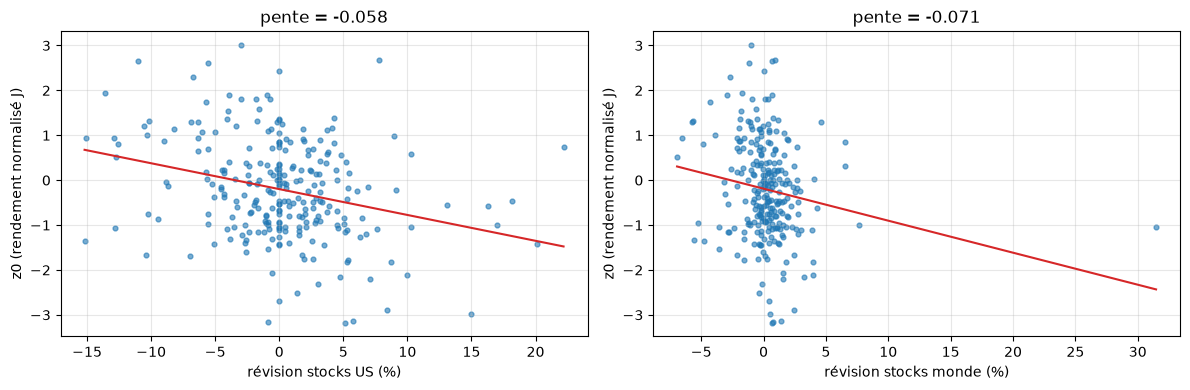

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, x, lab in [(ax[0], "us_es_rev", "révision stocks US (%)"), (ax[1], "world_es_rev", "révision stocks monde (%)")]:
    a.scatter(d2[x] * 100, d2["z0"], s=12, alpha=.6)
    b = np.polyfit(d2[x] * 100, d2["z0"], 1)
    xs = np.linspace(d2[x].min() * 100, d2[x].max() * 100, 50)
    a.plot(xs, np.polyval(b, xs), c="C3")
    a.set(xlabel=lab, ylabel="z0 (rendement normalisé J)", title=f"pente = {b[0]:.3f}")
plt.tight_layout()

# Robustesse : changement d'heure de publication et période récente
m = smf.ols("z0 ~ us_rev_z * post2013 + world_rev_z * post2013", d2).fit(cov_type="HC1")
print(m.summary().tables[1])

In [15]:
# Robustesse H2 : même régression par époque (.txt 2000-2010 ; PDF 2011-2015 ; .txt 2016-2026)
d2e = d2.assign(epoque=np.select([d2.date.dt.year <= 2010, d2.date.dt.year <= 2015],
                                 ["2000-2010 (.txt)", "2011-2015 (PDF)"], "2016-2026 (.txt)"))
for ep, sub in d2e.groupby("epoque"):
    m = smf.ols("z0 ~ us_rev_z + world_rev_z", sub).fit(cov_type="HC1")
    s, p = stats.spearmanr(sub.us_es_rev, sub.z0)
    print(f"{ep:18s} n={int(m.nobs):3d}  β US={m.params['us_rev_z']:+.3f} (p={m.pvalues['us_rev_z']:.3f})  "
          f"β monde={m.params['world_rev_z']:+.3f} (p={m.pvalues['world_rev_z']:.3f})  Spearman US/z0={s:+.2f} (p={p:.3f})")
# Rupture testée à plusieurs dates : l'effet US change-t-il nettement ?
for brk in [2010, 2013, 2016]:
    d2e["post"] = (d2e.date.dt.year >= brk).astype(int)
    m = smf.ols("z0 ~ us_rev_z * post + world_rev_z * post", d2e).fit(cov_type="HC1")
    print(f"rupture {brk} : interaction β US p={m.pvalues['us_rev_z:post']:.3f} (coef {m.params['us_rev_z:post']:+.3f})")


2000-2010 (.txt)   n=109  β US=-0.149 (p=0.068)  β monde=-0.077 (p=0.063)  Spearman US/z0=-0.18 (p=0.055)
2011-2015 (PDF)    n= 40  β US=-0.738 (p=0.000)  β monde=+0.020 (p=0.930)  Spearman US/z0=-0.61 (p=0.000)
2016-2026 (.txt)   n=107  β US=-0.326 (p=0.062)  β monde=-0.591 (p=0.008)  Spearman US/z0=-0.18 (p=0.062)
rupture 2010 : interaction β US p=0.007 (coef -0.376)
rupture 2013 : interaction β US p=0.046 (coef -0.329)
rupture 2016 : interaction β US p=0.713 (coef -0.071)


**Limite assumée.** La révision mensuelle n'est qu'une approximation de la surprise : une partie des révisions est anticipée (météo, *Crop Progress*, chiffres d'exportations hebdomadaires). Cela biaise le coefficient vers zéro (erreur de mesure sur la variable explicative), ce qui rend nos tests **conservateurs**.

## 7. H3 — Le ton du texte

Trois mesures du sentiment des paragraphes blé, de la plus simple à la plus flexible :

1. **Dictionnaire Loughran-McDonald (LM)** : proportion de mots positifs et négatifs, conçu pour les textes financiers.
2. **Jegadeesh-Wu (2013)** : au lieu d'imposer un dictionnaire, on **apprend le poids de chaque mot** à partir des réactions de prix passées, puis on score les textes hors échantillon.
3. **LLM** : un modèle de langage lit le paragraphe et donne un score haussier/baissier.

**Point de vigilance économique.** En matières premières, le ton « linguistique » et la direction du prix peuvent s'opposer : « *drought reduced production* » est un texte **négatif** au sens LM mais une nouvelle **haussière** pour le blé. C'est précisément pourquoi l'approche Jegadeesh-Wu, qui apprend le signe des mots à partir des prix, est intéressante ici.

In [16]:
def clean_tokens(text):
    # Un paragraphe absent du .txt vaut NaN (float, truthy) : on renvoie une liste vide, pas d'erreur.
    return re.findall(r"[a-z]+", text.lower()) if isinstance(text, str) else []

def load_lm_sets():
    # Dictionnaire LM : CSV 'Loughran-McDonald Master Dictionary' (site SRAF de Notre Dame)
    # placé dans data/, sinon le dictionnaire embarqué dans pysentiment2.
    csv = next(DATA_DIR.glob("Loughran-McDonald_MasterDictionary*.csv"), None)
    if csv is not None:
        d = pd.read_csv(csv)
        get = lambda col: set(d.loc[d[col] > 0, "Word"].str.lower())
        return get("Positive"), get("Negative"), get("Uncertainty"), csv.name
    import pysentiment2 as ps
    lm = ps.LM()
    return set(lm._posset), set(lm._negset), set(), "pysentiment2"

def lm_scores(text, pos, neg, unc):
    t = clean_tokens(text)
    n = max(len(t), 1)
    p = sum(w in pos for w in t); q = sum(w in neg for w in t); u = sum(w in unc for w in t)
    return {"lm_tone": (p - q) / (p + q) if p + q else 0.0, "lm_neg": q / n, "lm_unc": u / n}

try:
    LM_POS, LM_NEG, LM_UNC, lm_src = load_lm_sets()
    print("Dictionnaire LM :", lm_src, "|", len(LM_POS), "positifs,", len(LM_NEG), "négatifs")
    for c in TICKERS:
        sc = rep[f"txt_{c}"].apply(lambda t: pd.Series(lm_scores(t, LM_POS, LM_NEG, LM_UNC)))
        rep[[f"{k}_{c}" for k in sc.columns]] = sc.values
except Exception as e:
    print("Dictionnaire LM indisponible :", e)

Dictionnaire LM : Loughran-McDonald_MasterDictionary_1993-2021.csv | 347 positifs, 2345 négatifs


### 7.1 Contrôle de cohérence : le texte « dit-il » les chiffres ?

Les phrases du type « *ending stocks are raised 20 million bushels* » reprennent la révision numérique. Une règle simple (verbes de hausse ou de baisse dans les phrases qui mentionnent les stocks de fin) doit donc être fortement corrélée au signe de `us_es_rev`. Cela valide le parsing, et rappelle que **l'information textuelle utile pour H3 est celle qui reste une fois les chiffres connus**.

In [17]:
UP_RE = r"\b(rais\w*|increas\w*|higher|up|larger|boost\w*)\b"
DOWN_RE = r"\b(lower\w*|reduc\w*|decreas\w*|down|smaller|cut)\b"

def stocks_direction(text):
    if not isinstance(text, str):
        return np.nan
    s = 0
    for sent in re.split(r"(?<=[.;])\s+", text or ""):
        if re.search(r"ending stocks", sent, re.I):
            s += np.sign(len(re.findall(UP_RE, sent, re.I)) - len(re.findall(DOWN_RE, sent, re.I)))
    return np.sign(s)

rep["txt_stocks_dir"] = rep["txt_wheat"].apply(stocks_direction)
chk = rep.dropna(subset=["us_es_rev", "txt_stocks_dir"])
chk = chk[(chk.txt_stocks_dir != 0) & (chk.us_es_rev != 0)]
print(f"Accord signe(texte) = signe(révision US) : {(np.sign(chk.us_es_rev) == chk.txt_stocks_dir).mean():.0%} "
      f"sur {len(chk)} rapports")

Accord signe(texte) = signe(révision US) : 84% sur 192 rapports


### 7.2 Jegadeesh-Wu : apprendre le poids des mots à partir des prix

Dans Jegadeesh & Wu (2013), on régresse les rendements d'annonce sur la fréquence relative de chaque mot dans le document, $r_i = a + \sum_j b_j F_{ij} + \varepsilon_i$, et les coefficients $b_j$ deviennent les poids des mots.

Adaptations, imposées par la taille d'échantillon (~300 rapports blé) :
- **Mutualisation** des paragraphes blé, maïs et soja (~900 documents), chacun associé au rendement normalisé `z0` de *sa* céréale, avec un effet fixe par céréale (cible démeanée) ;
- **Régularisation ridge**, avec un λ choisi par validation croisée temporelle à l'intérieur de l'échantillon d'apprentissage ;
- **Walk-forward annuel strict** : pour scorer l'année Y, le modèle n'est entraîné que sur les années < Y. Aucun score n'utilise d'information future.

In [18]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

docs = pd.concat([pd.DataFrame({"date": events.loc[events.comm == c, "date"].values, "comm": c,
                                "text": events.loc[events.comm == c, f"txt_{c}"].values,
                                "z0": events.loc[events.comm == c, "z0"].values})
                  for c in TICKERS], ignore_index=True)
docs = docs.dropna(subset=["text", "z0"]).sort_values(["date", "comm"]).reset_index(drop=True)
docs["text"] = docs["text"].str.replace(r"\d+", " ", regex=True)     # les chiffres sont traités à part (H2)
docs["year"] = docs.date.dt.year

def word_freq(vec, texts):
    X = vec.transform(texts).astype(float).toarray()
    n = np.array([max(len(clean_tokens(t)), 1) for t in texts])[:, None]
    return X / n                                                     # F_ij = fréquence relative

def jw_walk_forward(docs, first_year=FIRST_TEST_YEAR, min_df=10):
    docs = docs.copy(); docs["jw"] = np.nan
    model = vec = None
    for Y in range(first_year, docs.year.max() + 1):
        tr, te = docs[docs.year < Y], docs[docs.year == Y]
        if len(te) == 0 or len(tr) < 100:
            continue
        vec = CountVectorizer(token_pattern=r"(?u)\b[a-z][a-z]+\b", lowercase=True,
                              min_df=min_df, stop_words="english").fit(tr.text)
        y = tr.z0 - tr.groupby("comm").z0.transform("mean")          # effet fixe céréale
        scaler = StandardScaler().fit(word_freq(vec, tr.text))
        model = RidgeCV(alphas=np.logspace(0, 5, 30), cv=TimeSeriesSplit(5)).fit(
            scaler.transform(word_freq(vec, tr.text)), y)
        docs.loc[te.index, "jw"] = model.predict(scaler.transform(word_freq(vec, te.text)))
    return docs, model, vec

docs, jw_model, jw_vec = jw_walk_forward(docs)
oos = docs.dropna(subset=["jw"])
def r2_oos(y, yhat):
    return 1 - ((y - yhat) ** 2).sum() / (y ** 2).sum()                # benchmark : prévision nulle
print("Hors échantillon :", len(oos), "documents")
pd.DataFrame({c: {"corr(jw, z0)": g.jw.corr(g.z0), "R² OOS": r2_oos(g.z0, g.jw),
                  "accord de signe": (np.sign(g.jw) == np.sign(g.z0)).mean(), "n": len(g)}
              for c, g in oos.groupby("comm")}).T

Hors échantillon : 647 documents


,"corr(jw, z0)",R² OOS,accord de signe,n
corn,0.0265,0.0006,0.5185,216.0000
soy,-0.0763,-0.0022,0.5488,215.0000
wheat,-0.0553,-0.0036,0.5046,216.0000


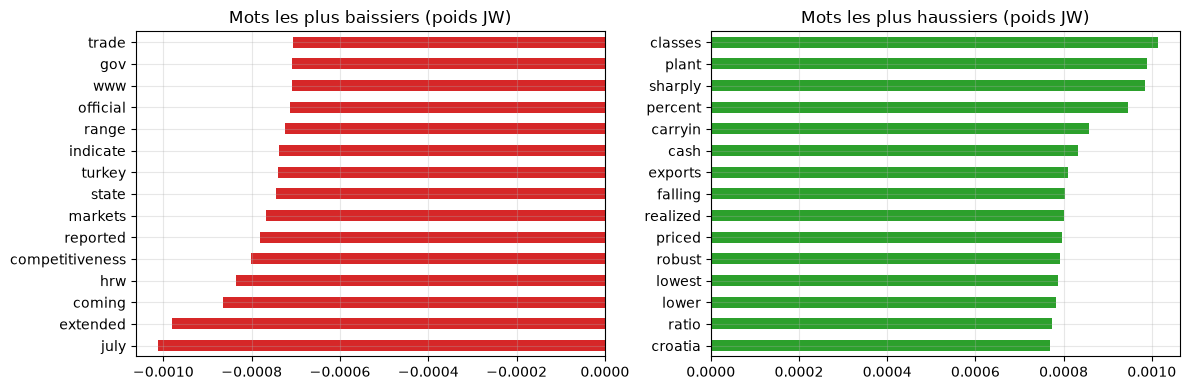

In [19]:
# Interprétation : mots aux poids les plus haussiers / baissiers dans le dernier modèle entraîné
w = pd.Series(jw_model.coef_, index=jw_vec.get_feature_names_out()).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
w.head(15).plot.barh(ax=ax[0], color="C3", title="Mots les plus baissiers (poids JW)")
w.tail(15).plot.barh(ax=ax[1], color="C2", title="Mots les plus haussiers (poids JW)")
plt.tight_layout()

**À discuter dans le rapport.** Les mots fortement pondérés sont-ils économiquement interprétables (*drought*, *reduced*, *tighter* côté haussier ; *record*, *raised*, *ample* côté baissier) ou capturent-ils des **régimes** (noms de pays, d'années de crise) qui ne se généralisent pas ? Le walk-forward protège contre le sur-apprentissage, mais pas contre un vocabulaire qui change avec les époques.

### 7.3 Score LLM

> **Statut : H3-LLM n'est pas évalué tant que `ANTHROPIC_API_KEY` n'est pas défini.** Dans ce cas la cellule ci-dessous ne fait aucun appel, la colonne `llm` reste vide et le score est exclu des tests (section 8, seuil `> 30` observations).

Le LLM lit le paragraphe blé (années masquées) et rend un score entre -1 (très baissier) et +1 (très haussier) pour le prix du blé CBOT. Les réponses sont mises en cache dans `data/llm_scores.json`.

> ⚠️ **Biais d'anticipation propre aux LLM.** Un modèle entraîné sur Internet a pu « voir » les commentaires de marché publiés après chaque WASDE. Masquer les années réduit le risque sans l'éliminer. Le test le plus propre se limite aux rapports **postérieurs à la date de coupure** des connaissances du modèle ; on présente les deux résultats.

In [20]:
LLM_CACHE = DATA_DIR / "llm_scores.json"
LLM_PROMPT = (
    "You are a grain market analyst. Below is the wheat section of a monthly USDA WASDE report "
    "(years have been masked). Based only on this text, judge whether the news it contains is bullish "
    "or bearish for CBOT wheat futures prices relative to the previous month's report.\n"
    'Answer ONLY with JSON: {"score": <number from -1 (very bearish) to 1 (very bullish)>, '
    '"reason": "<at most 20 words>"}\n\nTEXT:\n')

def mask_years(t):
    return re.sub(r"\b(19|20)\d{2}(/\d{2})?\b", "YYYY", t)

def llm_scores(texts, dates):
    cache = json.loads(LLM_CACHE.read_text()) if LLM_CACHE.exists() else {}
    if USE_LLM:
        import anthropic
        client = anthropic.Anthropic()
        for d, t in zip(dates, texts):
            k = f"{d:%Y-%m-%d}"
            if k in cache or not isinstance(t, str):
                continue
            try:
                msg = client.messages.create(model=LLM_MODEL, max_tokens=150, temperature=0,
                                             messages=[{"role": "user", "content": LLM_PROMPT + mask_years(t)}])
                out = msg.content[0].text
                cache[k] = float(json.loads(re.search(r"\{.*\}", out, re.S).group())["score"])
            except Exception as e:
                print(k, "erreur :", e)
            LLM_CACHE.write_text(json.dumps(cache))
    return pd.Series([cache.get(f"{d:%Y-%m-%d}", np.nan) for d in dates], index=dates.index)

rep["llm"] = llm_scores(rep["txt_wheat"], rep["date"])
print(f"Scores LLM disponibles : {rep.llm.notna().sum()} / {len(rep)}")
if not USE_LLM:
    print("H3-LLM non évalué : ANTHROPIC_API_KEY absente. Aucun appel API effectué.")

Scores LLM disponibles : 0 / 319
H3-LLM non évalué : ANTHROPIC_API_KEY absente. Aucun appel API effectué.


## 8. Le texte apporte-t-il de l'information au-delà des chiffres ?

C'est la question centrale. On compare, **sur le même échantillon hors échantillon** (années ≥ `FIRST_TEST_YEAR`) :

- (a) chiffres seuls : `z0 ~ révision US + révision monde` ;
- (b) chiffres + un score textuel (LM, JW ou LLM) ;
- (c) **score textuel orthogonalisé** : on retire d'abord du score ce qu'expliquent les chiffres, et on teste le résidu.

Un coefficient significatif sur le score orthogonalisé signifie que le ton contient une information que les tableaux ne contiennent pas.

In [21]:
jw_w = docs.loc[docs.comm == "wheat", ["date", "jw"]]
ew = ew.drop(columns=[c for c in ew if c in ("jw", "llm") or (c.startswith("lm_") and c.endswith("_wheat"))]).merge(jw_w, on="date", how="left") \
       .merge(rep[["date", "llm"] + [c for c in rep if c.startswith("lm_") and c.endswith("_wheat")]],
              on="date", how="left")
TEXT_SCORES = [s for s in ["lm_tone_wheat", "lm_neg_wheat", "jw", "llm"]
               if s in ew and ew[s].notna().sum() > 30]

base = ew[ew.date.dt.year >= FIRST_TEST_YEAR].dropna(subset=["z0", "us_rev_z", "world_rev_z"]).copy()
rows = {}
m0 = smf.ols("z0 ~ us_rev_z + world_rev_z", base).fit(cov_type="HC1")
rows["chiffres seuls"] = {"R²": m0.rsquared, "n": int(m0.nobs)}
for s in TEXT_SCORES:
    d = base.dropna(subset=[s]).copy()
    d["s_z"] = zscore(d[s])
    d["s_orth"] = zscore(sm.OLS(d["s_z"], sm.add_constant(d[["us_rev_z", "world_rev_z"]])).fit().resid)
    ma = smf.ols("z0 ~ us_rev_z + world_rev_z", d).fit(cov_type="HC1")
    mb = smf.ols("z0 ~ us_rev_z + world_rev_z + s_orth", d).fit(cov_type="HC1")
    rows[f"+ {s}"] = {"R²": mb.rsquared, "ΔR² vs chiffres": mb.rsquared - ma.rsquared,
                      "β texte orth.": mb.params["s_orth"], "t": mb.tvalues["s_orth"],
                      "p": mb.pvalues["s_orth"], "n": int(mb.nobs)}
h3 = pd.DataFrame(rows).T
h3

,R²,n,ΔR² vs chiffres,β texte orth.,t,p
chiffres seuls,0.1922,176.0000,NaN,NaN,NaN,NaN
+ lm_tone_wheat,0.1924,176.0000,0.0001,0.0126,0.1699,0.8651
+ lm_neg_wheat,0.1930,176.0000,0.0008,-0.0314,-0.4473,0.6547
+ jw,0.1923,176.0000,0.0001,-0.0085,-0.1547,0.8771


**Tests multiples.** On teste plusieurs scores textuels : un *p* < 5 % isolé n'est pas une découverte. Une correction de Bonferroni sur le nombre de scores testés donne un seuil plus honnête.

In [22]:
if "p" in h3:
    k = h3["p"].notna().sum()
    print(f"Seuil Bonferroni pour {k} scores : {0.05 / max(k, 1):.4f}")
    print(h3.loc[h3["p"].notna(), ["β texte orth.", "p"]].assign(signif_Bonferroni=lambda x: x.p < 0.05 / k))

Seuil Bonferroni pour 3 scores : 0.0167
                 β texte orth.      p  signif_Bonferroni
+ lm_tone_wheat         0.0126 0.8651              False
+ lm_neg_wheat         -0.0314 0.6547              False
+ jw                   -0.0085 0.8771              False


In [23]:
# Version prédictive : classification hors échantillon du signe de la réaction (walk-forward annuel)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

def wf_auc(df, feats, target="z0", first=FIRST_TEST_YEAR):
    df = df.dropna(subset=feats + [target]).copy()
    df["y"] = (df[target] > 0).astype(int)
    df["p"] = np.nan
    for Y in range(first, df.date.dt.year.max() + 1):
        tr, te = df[df.date.dt.year < Y], df[df.date.dt.year == Y]
        if len(te) == 0 or tr.y.nunique() < 2:
            continue
        sc = StandardScaler().fit(tr[feats])
        clf = LogisticRegression(C=1.0).fit(sc.transform(tr[feats]), tr.y)
        df.loc[te.index, "p"] = clf.predict_proba(sc.transform(te[feats]))[:, 1]
    o = df.dropna(subset=["p"])
    return roc_auc_score(o.y, o.p) if o.y.nunique() == 2 else np.nan, len(o)

nums_f = ["us_es_rev", "world_es_rev"]
auc = {"chiffres": wf_auc(ew, nums_f)}
for s in TEXT_SCORES:
    auc[f"chiffres + {s}"] = wf_auc(ew, nums_f + [s])
pd.DataFrame(auc, index=["AUC OOS (signe de z0)", "n"]).T

,AUC OOS (signe de z0),n
chiffres,0.6472,176.0000
chiffres + lm_tone_wheat,0.6325,176.0000
chiffres + lm_neg_wheat,0.6336,176.0000
chiffres + jw,0.6345,166.0000


## 9. Backtest

**Contrainte d'information.** Le WASDE sort à midi (heure de New York) ; avec des données journalières, on ne peut pas trader la réaction intrajournalière sans tricher. On se positionne donc à la **clôture de J** et on encaisse J+1 (ou J+1…J+5). Cela teste la **sous-réaction** : une partie de l'information est-elle encore incorporée après le jour de l'annonce ?

Signaux (tous connus à la clôture de J) :
- `chiffres` : long si les stocks US sont révisés à la baisse (signe de `-us_es_rev`) ;
- `momentum J` : dans le sens de la réaction du jour (signe de `r0`) ;
- `jw`, `llm`, `lm_tone_wheat` : signe du score textuel. Pour les scores LM, l'orientation (un ton « positif » est-il haussier ou baissier ?) est apprise uniquement sur les années antérieures à `FIRST_TEST_YEAR` ;
- `combo` : moyenne des signaux standardisés disponibles.

Coût : `COST_BPS` par aller simple. Significativité : test de permutation (les signes sont tirés au hasard 5 000 fois).

In [24]:
bt = ew[ew.date.dt.year >= FIRST_TEST_YEAR].copy()
bt["sig_chiffres"] = -bt["us_es_rev"]
bt["sig_momentum J"] = bt["r0"]
train = ew[ew.date.dt.year < FIRST_TEST_YEAR]
for s in TEXT_SCORES:
    # Orientation du score apprise sur la période d'avant-test uniquement (LM : ton positif ≠ haussier)
    rho = train[s].corr(train["z0"]) if s not in ("jw", "llm") else 1.0
    bt[f"sig_{s}"] = np.sign(rho if pd.notna(rho) else 1.0) * bt[s]
sig_cols = [c for c in bt if c.startswith("sig_")]
bt["sig_combo"] = pd.concat([zscore(bt[c]) for c in sig_cols], axis=1).mean(axis=1)
sig_cols.append("sig_combo")

def run_bt(df, sig_col, hold, cost_bps=COST_BPS, n_perm=5000):
    d = df.dropna(subset=[sig_col, hold])
    pos = np.sign(d[sig_col]).replace(0, np.nan).dropna()
    r = d.loc[pos.index, hold]
    pnl = pos * r - 2 * cost_bps / 1e4
    perm = np.array([(rng.choice([-1, 1], len(r)) * r).mean() for _ in range(n_perm)])
    years = max(d.date.dt.year.nunique(), 1)
    sr = pnl.mean() / pnl.std() * np.sqrt(len(pnl) / years)                  # Sharpe annualisé
    se = np.sqrt((1 + 0.5 * sr ** 2) / years)                               # erreur-type approchée (Lo, 2002)
    return pnl, {"PnL moyen / trade (bp)": pnl.mean() * 1e4, "hit rate": (pnl > 0).mean(),
                 "Sharpe annualisé": sr, "IC95 Sharpe (approx.)": f"[{sr - 1.96 * se:.2f} ; {sr + 1.96 * se:.2f}]",
                 "p permutation": (perm >= (pos * r).mean()).mean(), "n trades": len(pnl)}

results, curves = {}, {}
for hold in ["r_post1", "r_post5"]:
    for s in sig_cols:
        pnl, st = run_bt(bt, s, hold)
        results[(hold, s.replace("sig_", ""))] = st
        if hold == "r_post1":
            curves[s.replace("sig_", "")] = pd.Series(pnl.values, index=bt.loc[pnl.index, "date"]).cumsum()
pd.DataFrame(results).T

PnL moyen / trade (bp) hit rate Sharpe annualisé  \
r_post1 chiffres                    -25.4096   0.4506          -0.3381   
        momentum J                    2.2304   0.5000           0.0323   
        lm_tone_wheat               -13.0722   0.4643          -0.1723   
        lm_neg_wheat                 -0.2713   0.5032          -0.0035   
        jw                          -24.0258   0.4550          -0.3628   
        combo                        -7.0351   0.4726          -0.1022   
r_post5 chiffres                    -47.6498   0.5116          -0.3091   
        momentum J                    4.0489   0.5324           0.0288   
        lm_tone_wheat                -4.2706   0.5055          -0.0279   
        lm_neg_wheat                 72.3936   0.5529           0.4590   
        jw                          -16.0408   0.4861          -0.1157   
        combo                        14.2948   0.5530           0.1024   

                      IC95 Sharpe (approx.) p permutation n trades  
r_post1 chiffres             [-0.80 ; 0.12]        0.8744      162  
        momentum J           [-0.42 ; 0.48]        0.3028      200  
        lm_tone_wheat        [-0.63 ; 0.28]        0.6518      168  
        lm_neg_wheat         [-0.45 ; 0.45]        0.3850      157  
        jw                   [-0.83 ; 0.10]        0.8828      200  
        combo                [-0.55 ; 0.35]        0.5326      201  
r_post5 chiffres             [-0.77 ; 0.15]        0.8820      172  
        momentum J           [-0.42 ; 0.48]        0.3784      216  
        lm_tone_wheat        [-0.48 ; 0.42]        0.4796      182  
        lm_neg_wheat         [-0.01 ; 0.93]        0.0160      170  
        jw                   [-0.57 ; 0.34]        0.6346      216  
        combo                [-0.35 ; 0.55]        0.2566      217

Text(0, 0.5, '%')

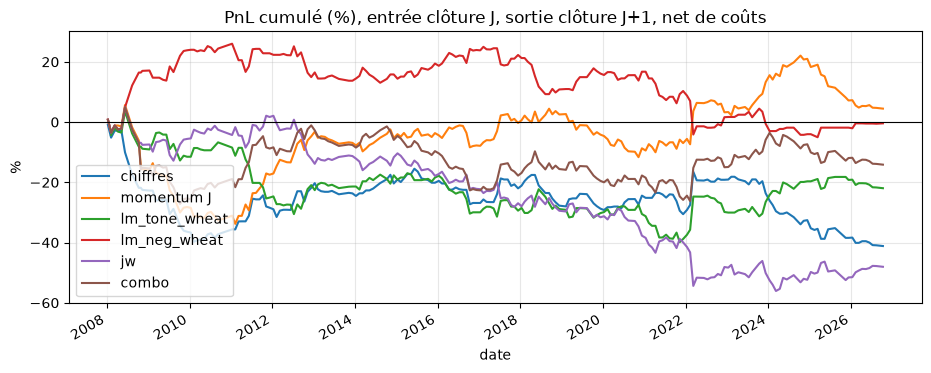

In [25]:
ax = pd.DataFrame(curves).ffill().mul(100).plot(figsize=(11, 4), title="PnL cumulé (%), entrée clôture J, sortie clôture J+1, net de coûts")
ax.axhline(0, c="k", lw=.8); ax.set_ylabel("%")

**À garder en tête.** Avec ~12 trades par an sur une quinzaine d'années, l'incertitude sur un Sharpe est énorme (son écart-type est de l'ordre de $\sqrt{1/T_{années}} \approx 0{,}25$). Un résultat de backtest est ici un **complément** aux tests statistiques des sections 5-8, pas une preuve à lui seul. Si des données intrajournalières étaient disponibles (CME DataMine, Databento), le test naturel serait une entrée à 12h01 (heure de New York), qui capterait la réaction du jour.

## 10. Placebos et robustesse

1. **Fausses dates** : on décale chaque date de WASDE de +10 séances. Aucun effet ne devrait apparaître.
2. **Maïs et soja** : mêmes tests H1/H2 avec leurs propres révisions de stocks. Un effet du même ordre renforce l'interprétation « information USDA » plutôt qu'un artefact propre au blé.
3. **Texte permuté** : on permute les scores JW entre rapports ; la corrélation obtenue doit être nulle en moyenne. La vraie corrélation est comparée à cette distribution.

In [26]:
idx_w = rets["wheat"].dropna().index
fake = idx_w[np.clip(idx_w.searchsorted(ev_days["wheat"]) + 10, 0, len(idx_w) - 1)]
placebo = pd.concat({"vraies dates": announcement_table("wheat", ev_days["wheat"]).loc["z_abs"],
                     "dates +10 séances": announcement_table("wheat", fake).loc["z_abs"]}, axis=1)
print("H1 sur |z| — vraies dates vs fausses dates")
placebo

H1 sur |z| — vraies dates vs fausses dates


,vraies dates,dates +10 séances
moy. WASDE,0.8971,0.6516
moy. autres,0.7922,0.8046
ratio,1.1324,0.8098
t HAC,2.6526,-4.4420
p Welch,0.0083,0.0000
p Mann-Whitney,0.0011,0.0000
n WASDE,303.0000,312.0000


In [27]:
rows = {}
for c, rev in [("wheat", "us_es_rev"), ("corn", "corn_es_rev"), ("soy", "soy_es_rev")]:
    e = events[events.comm == c].dropna(subset=["z0", rev]).copy()
    e["rev_z"] = zscore(e[rev])
    m = smf.ols("z0 ~ rev_z", e).fit(cov_type="HC1")
    h = announcement_table(c, ev_days[c]).loc["z_abs"]
    rows[c] = {"ratio vol. jour WASDE": h["ratio"], "t HAC": h["t HAC"],
               "β révision stocks": m.params["rev_z"], "t": m.tvalues["rev_z"], "n": int(m.nobs)}
pd.DataFrame(rows).T

,ratio vol. jour WASDE,t HAC,β révision stocks,t,n
wheat,1.1324,2.6526,-0.3007,-4.0659,277.0000
corn,1.4156,5.8124,-0.4727,-2.9011,161.0000
soy,1.2390,3.9286,-0.4177,-3.6139,159.0000


IC réel (JW, blé) = -0.055 ; p permutation = 0.798


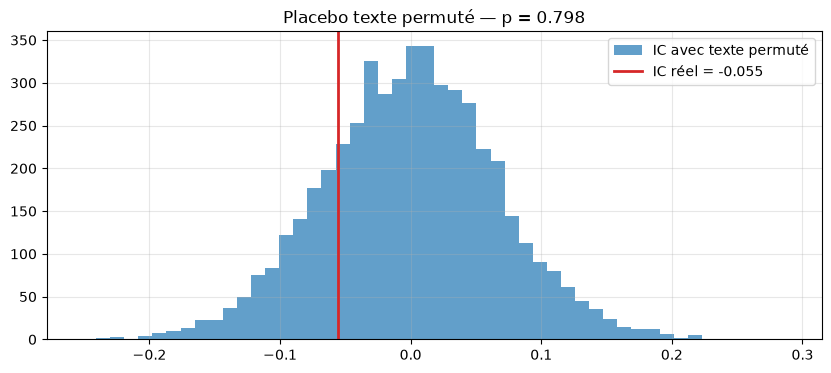

In [28]:
o = docs[(docs.comm == "wheat")].dropna(subset=["jw"])
true_ic = o.jw.corr(o.z0)
perm_ic = np.array([np.corrcoef(rng.permutation(o.jw.values), o.z0.values)[0, 1] for _ in range(5000)])
print(f"IC réel (JW, blé) = {true_ic:.3f} ; p permutation = {(perm_ic >= true_ic).mean():.3f}")
plt.hist(perm_ic, bins=50, alpha=.7, label="IC avec texte permuté")
plt.axvline(true_ic, c="C3", lw=2, label=f"IC réel = {true_ic:.3f}")
plt.legend(); plt.title(f"Placebo texte permuté — p = {(perm_ic >= true_ic).mean():.3f}");

## 11. Limites et conclusion

**Statut.** Toutes les sections s'exécutent sans erreur. Seul H3-LLM n'est pas évalué, faute de clé API.

**Réponse à la question du titre.** Sur le blé, le WASDE s'accompagne d'une volatilité plus forte et d'un rendement moyen négatif le jour de l'annonce. Les stocks révisés à la hausse font baisser le prix le même jour, et cet effet varie selon l'époque (fort en 2011-2015). Le ton du texte n'apporte rien au-delà des chiffres, et le backtest ne donne pas de rentabilité robuste.

**Conclusion par hypothèse**

| Hypothèse | Chiffre clé | p-value | Verdict |
|---|---|---|---|
| **H1** prime d'annonce et volatilité (blé, n = 303) | rendement moyen −0,30 % les jours WASDE contre +0,03 % ; ratio de \|z\| 1,13 | Welch 0,013 (moyenne) ; 0,008 (\|z\|, t HAC 2,65) | Volatilité plus forte, mais rendement moyen négatif : pas de prime au sens de Savor & Wilson. Le placebo des fausses dates n'est pas neutre (ratio 0,81). Rendement moyen négatif dans les quatre sous-périodes, significatif seulement sur l'ensemble ; 18 années sur 27 négatives, test de signe p = 0,010. |
| **H2** surprise numérique (signe attendu : négatif, n = 256) | β révision US = −0,27 ; β monde = −0,11 ; R² = 0,088 | HC1 : 0,0004 (US) ; 0,011 (monde) | Signe attendu, significatif le jour même. Dérive post-annonce non significative : J+1 β = +0,0009, p = 0,55. Effet US très fort en 2011-2015 (β = −0,74, Spearman −0,61, n = 40), plus faible en 2000-2010 et 2016-2026. Variation par époque, pas une rupture nette à 2013 (rupture 2016 : p = 0,71). |
| **H3** ton, LM et Jegadeesh-Wu (2000-2026, 176 hors échantillon) | ΔR² ≤ 0,001 ; AUC 0,647 sans texte, 0,633 avec ton LM ; corrélation JW hors échantillon = −0,06 | ton LM 0,87 ; LM négatif 0,65 ; JW 0,88 ; permutation JW 0,80 | Aucune information au-delà des chiffres. Aucun score ne survit à Bonferroni (seuil 0,017). |
| **H3-LLM** | — | — | Non évalué : `ANTHROPIC_API_KEY` absente, aucun appel effectué. |
| **Backtest**, signal chiffres (entrée clôture J, net de coûts, 162 trades) | sortie J+1 : −25 pb par trade, Sharpe −0,34, IC95 [−0,80 ; 0,12] ; sortie J+5 : −48 pb, Sharpe −0,31 | J+1 : 0,87 ; J+5 : 0,88 (permutation) | Pas de rentabilité significative. Après la réaction du jour, le prix revient en partie (β J+1 positif) : pas de sous-réaction exploitable. |
| **Backtest**, score LM négatif | sortie J+1 : 0 pb, Sharpe 0,00 ; sortie J+5 : +72 pb par trade, Sharpe 0,46, IC95 [−0,01 ; 0,93] | J+1 : 0,39 ; J+5 : 0,016 | Résultat qui dépend de l'horizon. Avec 12 variantes testées, le seuil de Bonferroni est 0,004 : non retenu. |

**Limites (à reprendre dans le rapport)**
- **Tableaux des PDF approximés** : pour 2011-2015 et 9 rapports de 2016, les stocks viennent du PDF (tonnes à une décimale pour le maïs). Les révisions de maïs de ces années sont donc un peu moins précises. Cela touche surtout le placebo maïs.
- **Effet H2 variable selon l'époque** : fort en 2011-2015 (PDF, n = 40), plus faible en 2000-2010 et 2016-2026. Il reste fort sans les 3 plus fortes révisions (β −0,72). Ce n'est pas une rupture nette à 2013 : le passage à midi devrait diluer l'effet, pas le renforcer. À présenter comme une variation par époque, à expliquer, sur un petit sous-échantillon.
- **Historique de prix** : la série blé commence le 2000-07-17. Les rapports de janvier à juillet 2000 ne sont pas testés.
- **Surprise approximée** par la révision mensuelle (pas de consensus public) : erreur de mesure, donc biais vers zéro.
- **Données journalières** seulement : la réaction du jour J inclut la matinée avant publication depuis le passage à midi, et le backtest ne peut pas exploiter la réaction intrajournalière.
- **Rapports simultanés** (*Crop Production*) : l'effet mesuré est celui du « jour WASDE ». Le maïs (ratio 1,42) et le soja (1,24) montrent un effet de volatilité plus fort que le blé (1,13), compatible avec cette confusion.
- **Contrat continu** : 131 rolls blé détectés, 118 le jour de la dernière séance théorique. Neuf jours WASDE coïncident avec un roll et sont écartés (8 événements blé perdus au total).
- **Placebo des fausses dates non neutre** : les dates +10 séances ont un |z| inférieur à la moyenne (ratio 0,81, t = −4,4). Une régularité calendaire peut donc peser sur H1. La prime de rendement négative est de même signe dans les quatre sous-périodes ; elle n'est significative que sur l'ensemble.
- **Taille d'échantillon** : 303 annonces blé pour H1, 256 pour H2, 176 hors échantillon pour H3. Le backtest porte sur 162 trades : IC95 du Sharpe large.
- **LLM** : risque de mémorisation des réactions de marché. H3-LLM non évalué.
- **Tests multiples** : Bonferroni sur les scores textuels (section 8). Les 12 variantes du backtest ne sont pas corrigées dans la sortie.

**Références**
- Savor, P. & Wilson, M. (2014). *Asset pricing: A tale of two days.* Journal of Financial Economics.
- Jegadeesh, N. & Wu, D. (2013). *Word power: A new approach for content analysis.* Journal of Financial Economics.
- Loughran, T. & McDonald, B. (2011). *When is a liability not a liability? Textual analysis, dictionaries, and 10-Ks.* Journal of Finance.
- Isengildina-Massa, O., Irwin, S., Good, D. & Gomez, J. (2008). *The impact of situation and outlook information in corn and soybean futures markets: Evidence from WASDE reports.* Journal of Agricultural and Applied Economics.
- Adjemian, M. (2012). *Quantifying the WASDE announcement effect.* American Journal of Agricultural Economics.
- Lo, A. (2002). *The statistics of Sharpe ratios.* Financial Analysts Journal.

## Questions probables du jury

**1. Pourquoi mesurer la surprise par la révision mensuelle des stocks ?**
Il n'existe pas de consensus d'analystes accessible gratuitement. La révision par rapport au rapport précédent est la meilleure approximation disponible. Elle est bruitée : une partie des révisions est déjà anticipée (météo, *Crop Progress*, exportations hebdomadaires). L'erreur de mesure biaise le coefficient vers zéro, donc les tests sont conservateurs.

**2. Pourquoi la révision et pas le niveau des stocks ?**
Un niveau de stocks élevé mais attendu ne fait pas bouger le prix : seule la partie inattendue compte. Le niveau est connu avant l'annonce, la révision est ce qui change l'information. C'est le même raisonnement que la surprise en macro (FOMC).

**3. Quels sont les principaux biais ?**
- *Look-ahead* : chaque rapport n'est utilisé qu'à partir de sa date de publication, et les scores textuels sont walk-forward (le modèle de l'année Y n'utilise que les années < Y).
- *Heure de publication* : 8h30 avant 2013, 12h ensuite. Une indicatrice `post2013` contrôle ce changement.
- *Contrat continu* : les rolls faussent les rendements de jour d'annonce. Ils sont retirés par détection sur le volume.
- *Sélection* : seuls les rapports disponibles dans l'archive sont utilisés, et certains mois manquent (section 1).

**4. Pourquoi pas de test intrajournalier ?**
Les données disponibles sont journalières. Le rapport sort à 12h (heure de New York), en pleine séance : le rendement clôture à clôture mélange la matinée et l'annonce. Une entrée à 12h01 demanderait des données minute par minute (CME DataMine, Databento). À la place, on teste la sous-réaction : entrée à la clôture de J, sortie à J+1 ou J+1…J+5.

**5. Comment isoler l'effet WASDE de celui de *Crop Production* ?**
Les deux rapports sortent le même jour, donc on ne peut pas les séparer avec des données journalières. On mesure l'effet du « jour WASDE » et on le vérifie par des placebos : fausses dates (+10 séances) et maïs/soja, qui ont leurs propres révisions. L'interprétation reste « information USDA », pas « WASDE seul ». Le maïs et le soja montrent un effet de volatilité plus fort que le blé (ratio 1,42 et 1,24 contre 1,13), ce qui va dans ce sens sans le trancher.

**6. Le contrat continu n'introduit-il pas des artefacts ?**
Oui, c'est un risque réel. Le saut de prix au roll est un spread calendaire, pas un rendement. La détection repose sur le volume, indépendamment des rendements, pour ne pas effacer de vraies réactions. L'alternative propre est une série *back-adjusted* à partir des contrats individuels. La fonction `load_prices` accepte un CSV de remplacement.

**7. Ne risque-t-on pas des faux positifs avec tant de scores textuels ?**
Oui, c'est pourquoi on applique une correction de Bonferroni sur les scores testés (section 8), et qu'on ajoute un placebo par permutation du texte (section 10). Bonferroni est conservateur : il vaut mieux le lire comme une borne haute du risque, pas comme une contrainte à atteindre.

**8. Le LLM n'a-t-il pas vu les commentaires de marché après les rapports ?**
C'est un biais possible de mémorisation. Les années sont masquées dans le texte, et le test le plus propre se limite aux rapports postérieurs à la date de coupure du modèle. Si `ANTHROPIC_API_KEY` n'est pas défini, H3-LLM n'est pas évalué et la conclusion le dit.
